> ℹ️ **Über dieses Notebook**
>
> - Das ist ein möglicher Lösungs-Weg für [../De/01_loading_the_data.ipynb](../De/01_loading_the_data.ipynb) und [../De/02_king_county_project.ipynb](../De/02_king_county_project.ipynb).
> - Es gibt viele richtige Wege. Dieser ist einfach und nachvollziehbar.
> - Alle Daten-Pfade zeigen einen Ordner nach oben, also `../data/`.
> - Teil A speichert `../data/eda.csv`. Teil B lädt diese Datei.
> - Das ganze Notebook rechnet etwa zwei Minuten.
> - Schrift-Art und Schrift-Größe stellst du im Editor ein.

# Lösungs-Weg: King County House Prices

Lesezeit: ca. 60 Minuten mit Ausführen

## 🎯 Das lernst du hier

1. Du siehst für jeden Schritt, welche Funktion du brauchst und warum.
2. Du siehst eine vollständige Lösung, die ohne Fehler läuft.
3. Du kannst deine eigenen Zahlen mit diesen Zahlen vergleichen.

## 🗺️ Ablauf

| Abschnitt | Thema | Original-Aufgabe |
| :--- | :--- | :--- |
| 1️⃣ Teil A, Schritte A1 bis A6 | Tabellen laden, prüfen, verknüpfen, speichern | Notebook 01, Aufgaben 1 bis 6 |
| 2️⃣ Teil B, Schritte B1 bis B3 | Ziel, Daten, Aufteilung | Notebook 02, Aufgaben 1 bis 3 |
| 3️⃣ Teil B, Schritte B4 und B5 | Untersuchen und Basis-Modelle | Notebook 02, Aufgaben 4 und 5 |
| 4️⃣ Teil B, Schritte B6 und B7 | Pipeline und Abstimmung | Notebook 02, Aufgaben 6 und 7 |
| 5️⃣ Teil B, Schritt B8 | Bewerten auf den Test-Daten | Notebook 02, Aufgabe 8 |

Die Begriffe stehen im [Glossar](zusammenfassung.ipynb#glossar).

## 📖 Benötigte Funktionen

| Funktion | Wofür | Schritt |
| :--- | :--- | :--- |
| `pd.read_csv()` | eine CSV-Datei als DataFrame laden | A1, B2 |
| `.nunique()` | verschiedene Werte einer Spalte zählen | A2 |
| `.is_unique` | prüfen, ob kein Wert doppelt vorkommt | A3 |
| `.isin()` und `~` | Werte suchen, die in einer anderen Spalte fehlen | A4 |
| `.merge()` | zwei Tabellen über einen Schlüssel verknüpfen | A5 |
| `.to_csv()` | einen DataFrame als CSV-Datei speichern | A6 |
| `train_test_split()` | Daten in Trainings-Daten und Test-Daten teilen | B3 |
| `.corr()`, `.skew()`, `.isna()` | Zusammenhänge, Schiefe und Lücken finden | B4 |
| `DummyRegressor` | das Mittelwert-Basis-Modell | B5 |
| `SimpleImputer`, `StandardScaler`, `OneHotEncoder` | Auffüllen, Skalieren und One-Hot-Kodierung | B6 |
| `ColumnTransformer`, `Pipeline` | Vorbereitung und Modell zu einem Objekt verbinden | B6 |
| `Ridge`, `PolynomialFeatures` | lineare Modelle ohne und mit Polynom-Merkmalen | B6, B7 |
| `KFold`, `RandomizedSearchCV`, `GridSearchCV` | Kreuz-Validierung, Zufalls-Suche und Gitter-Suche | B7 |
| `root_mean_squared_error`, `mean_absolute_error`, `r2_score` | die drei Metriken | B8 |
| `pd.qcut()` | Test-Häuser in Preis-Viertel teilen | B8 |

## 1️⃣ Teil A: Die Daten laden und verknüpfen

### Schritt A1: Die zwei Tabellen laden

- Was: Du liest beide CSV-Dateien ein.
- Warum: Erst dann kannst du ihre Spalten vergleichen.

In [1]:
import pandas as pd

# Beide Tabellen laden
sales = pd.read_csv("../data/king_county_house_sales.csv")
details = pd.read_csv("../data/king_county_house_details.csv")
print(f"sales:   {sales.shape[0]:>6} rows, {sales.shape[1]} columns")
print(f"details: {details.shape[0]:>6} rows, {details.shape[1]} columns")

sales:    21597 rows, 4 columns
details:  21420 rows, 19 columns


👀 Worauf achten:

- `sales` hat 21.597 Zeilen, `details` hat 21.420 Zeilen.
- Es gibt also mehr Verkäufe als Häuser.

### Schritt A2: Zeilen und eindeutige Schlüssel zählen

- Was: Du zählst Zeilen und verschiedene Werte der Schlüssel-Spalten.
- Warum: So erkennst du, ob ein Haus mehrmals verkauft wurde.

In [2]:
print(f"sales rows:          {len(sales)}")
print(f"unique house_id:     {sales['house_id'].nunique()}")
print(f"details rows:        {len(details)}")
print(f"unique details id:   {details['id'].nunique()}")
# Wie oft wurde ein Haus höchstens verkauft?
print("max sales per house:", sales["house_id"].value_counts().max())

sales rows:          21597
unique house_id:     21420
details rows:        21420
unique details id:   21420
max sales per house: 3


👀 Worauf achten:

- 21.597 Verkäufe, aber nur 21.420 verschiedene Häuser.
- 176 Häuser wurden mehr als einmal verkauft, eines sogar 3-mal.
- Die Beziehung ist also Eins-zu-viele.

Antworten auf die drei Fragen aus Notebook 01:

1. `house_id` in `sales` verweist auf ein Haus, `id` in `details` kennzeichnet es.
2. Eins-zu-viele: Ein Haus kann mehrere Verkäufe haben.
3. Erwartet werden 21.597 Zeilen, eine pro Verkauf.

### Schritt A3: Prüfen, ob der Schlüssel eindeutig ist

- Was: Du prüfst, ob jede `id` in `details` nur einmal vorkommt.
- Warum: Ein doppelter Schlüssel würde Verkäufe still kopieren.

In [3]:
print("every id is unique:", details["id"].is_unique)

every id is unique: True


👀 Worauf achten: Das Ergebnis ist `True`. Die Verknüpfung kann keine Zeilen kopieren.

### Schritt A4: Die Schlüssel beider Tabellen vergleichen

- Was: Du zählst Verkäufe ohne Haus und Häuser ohne Verkauf.
- Warum: Das entscheidet, ob die Verknüpfungs-Art eine Rolle spielt.

In [4]:
# isin markiert Treffer, ~ dreht sie um, sum zählt den Rest
print("sales without house details:", (~sales["house_id"].isin(details["id"])).sum())
print("houses without a sale:      ", (~details["id"].isin(sales["house_id"])).sum())

sales without house details: 0
houses without a sale:       0


👀 Worauf achten:

- Beide Zahlen sind 0. Die Tabellen passen vollständig zusammen.
- Jede Verknüpfungs-Art liefert hier dasselbe Ergebnis.
- `how="left"` ist trotzdem die sichere Wahl. Dann bleibt jeder Verkauf erhalten, auch wenn ein Haus fehlen sollte.

### Schritt A5: Die zwei Tabellen verknüpfen

- Was: Du hängst `details` über den Schlüssel an `sales` an.
- Warum: Für das Modell brauchst du Preis und Haus-Merkmale in einer Zeile.

In [5]:
df = sales.merge(
    details,
    left_on="house_id",
    right_on="id",
    how="left",
    suffixes=("", "_details"),
)

print(f"combined: {df.shape[0]} rows, {df.shape[1]} columns")
# Stoppt mit Fehler, wenn die Verknüpfung Zeilen kopiert hat
assert len(df) == len(sales), "The combined table should have exactly one row per sale"
df.head()

combined: 21597 rows, 23 columns


,date,price,house_id,id,id_details,bedrooms,bathrooms,sqft_living,sqft_lot,floors,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2014-10-13,221900.0,7129300520,1,7129300520,3.0,1.00,1180.0,5650.0,1.0,...,7,1180.0,0.0,1955,0.0,98178,47.5112,-122.257,1340.0,5650.0
1,2014-12-09,538000.0,6414100192,2,6414100192,3.0,2.25,2570.0,7242.0,2.0,...,7,2170.0,400.0,1951,1991.0,98125,47.7210,-122.319,1690.0,7639.0
2,2015-02-25,180000.0,5631500400,3,5631500400,2.0,1.00,770.0,10000.0,1.0,...,6,770.0,0.0,1933,NaN,98028,47.7379,-122.233,2720.0,8062.0
3,2014-12-09,604000.0,2487200875,4,2487200875,4.0,3.00,1960.0,5000.0,1.0,...,7,1050.0,910.0,1965,0.0,98136,47.5208,-122.393,1360.0,5000.0
4,2015-02-18,510000.0,1954400510,5,1954400510,3.0,2.00,1680.0,8080.0,1.0,...,8,1680.0,0.0,1987,0.0,98074,47.6168,-122.045,1800.0,7503.0


👀 Worauf achten:

- 21.597 Zeilen und 23 Spalten.
- Die zweite `id` heißt jetzt `id_details`.

### Schritt A6: Die neue Tabelle speichern

- Was: Du schreibst die Tabelle nach `../data/eda.csv`.
- Warum: Notebook 02 lädt diese Datei und wiederholt die Verknüpfung nicht.

In [6]:
# index=False: keine extra Spalte mit Zeilen-Nummern
df.to_csv("../data/eda.csv", index=False)
check = pd.read_csv("../data/eda.csv")
print(f"{check.shape[0]} rows, {check.shape[1]} columns")

21597 rows, 23 columns


## 2️⃣ Teil B: Ziel, Daten und Aufteilung

### Schritt B1: Das Ziel und die Metrik festlegen

- Ziel: den Verkaufs-Preis möglichst genau vorhersagen.
- Haupt-Metrik: **RMSE**. Er ist in Dollar und bestraft große Fehler stärker.
- Zusätzlich: **MAE** als typischer Fehler in Dollar, **R²** als erklärter Anteil.

Zuerst kommen alle Imports aus Notebook 02.

In [7]:
# Alle Bibliotheken für das Projekt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

### Schritt B2: Die Daten holen

- Was: Du lädst die in Schritt A6 gespeicherte Tabelle.
- Warum: Notebook 02 beginnt mit dieser Datei.

In [8]:
df = pd.read_csv("../data/eda.csv")
df.shape

(21597, 23)

### Schritt B3: Die Daten aufteilen

- Was: 80 % Trainings-Daten, 20 % Test-Daten, fester `random_state`.
- Warum: Die Test-Daten bleiben bis Schritt B8 gesperrt. So messen sie am Ende ehrlich.

In [9]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
print(df_train.shape, df_test.shape)

(17277, 23) (4320, 23)


👀 Worauf achten: 17.277 Zeilen zum Trainieren, 4.320 Zeilen zum Testen. Beide enthalten noch `price`.

## 3️⃣ Teil B: Untersuchen und Basis-Modelle

### Schritt B4: Die Trainings-Daten untersuchen

- Was: Korrelation, Schiefe, fehlende Werte und doppelte Information.
- Warum: Daraus folgen deine Änderungen von Hand und die Regel für das Regel-Basis-Modell.

In [10]:
# Korrelation jeder Zahlen-Spalte mit dem Preis
df_train.corr(numeric_only=True)["price"].sort_values(ascending=False)

# Schiefe: große positive Werte bedeuten einen langen Ausläufer nach rechts
df_train.skew(numeric_only=True).sort_values(ascending=False)

# Fehlende Werte pro Spalte
df_train.isna().sum()

# Gleiche Information: Wohnfläche = Fläche über dem Boden + Keller
known = df_train.dropna(subset=["sqft_basement"])
(known["sqft_living"] == known["sqft_above"] + known["sqft_basement"]).all()

np.True_

#### Was bedeuten die Spalten?

Fläche in Quadrat-Fuß (`sqft`): 1 sqft ≈ 0,093 m², 1.000 sqft ≈ 93 m².

| Spalte | Bedeutung | Werte |
| :--- | :--- | :--- |
| `date` | Datum des Verkaufs | Mai 2014 bis Mai 2015 |
| `price` | Verkaufs-Preis, die Ziel-Variable | Dollar |
| `id`, `house_id`, `id_details` | Kennungen: Zeilen-Nummer, Haus-ID, Haus-ID aus `details` | keine Information über den Preis |
| `bedrooms` | Anzahl Schlafzimmer | 1 bis 11 |
| `bathrooms` | Anzahl Badezimmer, Teil-Bäder zählen anteilig | 0,5 = WC + Waschbecken, 0,75 = mit Dusche, 1 = mit Badewanne |
| `sqft_living` | Wohnfläche | sqft |
| `sqft_lot` | Grundstücks-Fläche | sqft |
| `floors` | Anzahl Stockwerke, halbe = ausgebautes Dach-Geschoss | 1 bis 3,5 |
| `waterfront` | Grundstück liegt direkt am Wasser | 0 = nein, 1 = ja |
| `view` | Qualität der Aussicht | 0 = keine bis 4 = hervorragend |
| `condition` | Zustand des Hauses, gemessen am Alter | 1 = schlecht, 3 = durchschnittlich, 5 = sehr gut |
| `grade` | Bau-Qualität und Design nach der Skala von King County | 1–3 unter Standard, 7 = Durchschnitt, 11–13 = Luxus |
| `sqft_above` | Wohnfläche über dem Boden | sqft |
| `sqft_basement` | Wohnfläche im Keller | sqft |
| `yr_built` | Baujahr | 1900 bis 2015 |
| `yr_renovated` | Jahr der letzten Renovierung | 0 = nie renoviert |
| `zipcode` | Postleitzahl, also die Lage | 70 verschiedene |
| `lat`, `long` | Breiten- und Längen-Grad | Lage auf der Karte |
| `sqft_living15` | mittlere Wohnfläche der 15 nächsten Nachbar-Häuser | sqft |
| `sqft_lot15` | mittlere Grundstücks-Fläche der 15 nächsten Nachbar-Häuser | sqft |

- `waterfront`, `view`, `condition` und `grade` sind Kategorien mit Rang-Folge. Höher heißt besser, deshalb dürfen sie als Zahl ins Modell.
- `zipcode` ist eine Kategorie ohne Rang-Folge. 98004 ist nicht „mehr" als 98001. Deshalb bekommt sie in Schritt B6 eine One-Hot-Kodierung.


In [ ]:
# Korrelation aller Zahlen-Spalten untereinander, ohne die Kennungen
corr = df_train.drop(columns=["id", "house_id", "id_details"]).corr(numeric_only=True)
# Die obere Hälfte ist ein Spiegel der unteren, deshalb ausblenden
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Korrelation der Merkmale (Trainings-Daten)")
plt.show()


👀 Worauf achten:

| Paar | Korrelation | Bedeutung |
| :--- | :--- | :--- |
| `sqft_living` und `sqft_above` | 0,88 | fast dieselbe Information, die meisten Häuser haben wenig Keller |
| `sqft_living` und `grade` | 0,76 | große Häuser sind meist auch hochwertig gebaut |
| `sqft_living` und `sqft_living15` | 0,76 | große Häuser stehen neben großen Häusern |
| `sqft_living` und `bathrooms` | 0,76 | mehr Fläche, mehr Bäder |
| `sqft_lot` und `sqft_lot15` | 0,71 | große Grundstücke liegen nebeneinander |
| `condition` und `yr_built` | −0,37 | `condition` wird relativ zum Alter vergeben |
| `zipcode` und `long` | −0,56 | die Postleitzahlen steigen grob von Ost nach West |

- Viele Flächen-Spalten und `grade` hängen stark zusammen. Für ein lineares Modell ist das doppelte Information. `Ridge` dämpft das Problem.
- `condition` hängt kaum mit dem Preis zusammen (0,04).
- `zipcode` hat −0,05, als Zahl sagt die Postleitzahl also nichts aus. Erst als Kategorie zeigt sie die Lage.


In [ ]:
# Median-Preis je Stufe der Kategorie-Spalten
ranked = ["waterfront", "view", "condition", "grade"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, ranked):
    df_train.groupby(col)["price"].median().plot.bar(ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Stufe")
axes[0].set_ylabel("Median-Preis in Dollar")
plt.tight_layout()
plt.show()


👀 Worauf achten:

| Spalte | Median-Preis je Stufe | Deutung |
| :--- | :--- | :--- |
| `waterfront` | 0: 450.000, 1: 1.600.000 | Lage am Wasser verdreifacht den Preis, aber nur 118 Häuser |
| `view` | 0: 434.000, 1–3: 680.000–800.000, 4: 1.200.000 | jede Aussicht hebt den Preis deutlich |
| `condition` | 1–2: 270.000–280.000, 3–4: 440.000–450.000, 5: 530.000 | wirkt nur an den Rändern, 3 und 4 sind fast gleich |
| `grade` | 7: 375.000, 9: 725.000, 11: 1.290.000, 13: 3.200.000 | steigt mit jeder Stufe, ab 7 fast exponentiell |

- `grade` ist die stärkste Kategorie. Sie misst Bau-Qualität, nicht Zustand.
- `condition` hängt schwach mit dem Preis zusammen, weil fast alle Häuser Stufe 3 oder 4 haben.


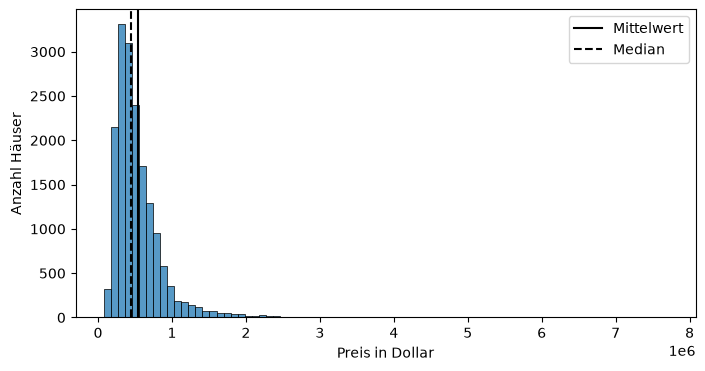

In [11]:
# Der Preis ist schief: wenige sehr teure Häuser ziehen den Mittelwert nach oben
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df_train["price"], bins=80, ax=ax)
ax.set_xlabel("Preis in Dollar")
ax.set_ylabel("Anzahl Häuser")
ax.axvline(df_train["price"].mean(), color="black", label="Mittelwert")
ax.axvline(df_train["price"].median(), color="black", linestyle="--", label="Median")
ax.legend()
plt.show()

👀 Worauf achten:

| Frage | Ergebnis |
| :--- | :--- |
| Stärkste Korrelation mit dem Preis | `sqft_living` 0,70, `grade` 0,67, `sqft_above` 0,60 |
| Am stärksten schief | `sqft_lot` 13,37, `waterfront` 11,28, `sqft_lot15` 8,90, `price` 3,95 |
| Fehlende Werte | `yr_renovated` 17,8 %, `waterfront` 11,0 %, `sqft_basement` 2,1 %, `view` 0,3 % |
| Gleiche Information | `sqft_living` = `sqft_above` + `sqft_basement`, und `id_details` = `house_id` |

- Mittelwert 541.519 Dollar, Median 450.000 Dollar. Der Mittelwert liegt höher, weil der Preis schief ist.
- In `yr_renovated` sind 78,8 % der Werte 0. Eine Ja-Nein-Spalte `renovated` ist deshalb klarer als das Jahr.

Deine Änderungen von Hand fasst du in einer Funktion zusammen:

| Änderung | Grund |
| :--- | :--- |
| `age_at_sale` neu | Alter beim Verkauf sagt mehr als das Baujahr allein |
| `renovated` neu | ersetzt `yr_renovated` mit vielen Nullen und Lücken |
| `id`, `house_id`, `id_details` weg | Kennungen tragen keine Information über den Preis |
| `date` weg | als Text kann das Modell es nicht nutzen, das Jahr steckt in `age_at_sale` |
| `sqft_basement` weg | ist genau `sqft_living` minus `sqft_above` und hat Lücken |

In [12]:
def prepare(data):
    # Alle Änderungen von Hand an einer Stelle, für Trainings- und Test-Daten
    data = data.copy()
    sale_year = pd.to_datetime(data["date"]).dt.year
    data["age_at_sale"] = sale_year - data["yr_built"]
    data["renovated"] = (data["yr_renovated"] > 0).astype(int)
    return data.drop(columns=["id", "house_id", "id_details", "date",
                              "yr_renovated", "sqft_basement"])

### Schritt B5: Merkmale und Ziel-Variable trennen, zwei Basis-Modelle

- Was: `X_train` und `y_train`, dann zwei einfache Modelle.
- Warum: Ein echtes Modell ist nur gut, wenn es diese einfachen Modelle schlägt.
- Regel: Der Preis pro Quadrat-Fuß, gelernt als Median auf den Trainings-Daten.

In [13]:
train = prepare(df_train)
X_train = train.drop(columns="price")
y_train = train["price"]

# Mittelwert-Basis-Modell: der mittlere Preis der Trainings-Daten für jedes Haus
mean_baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)

# Regel-Basis-Modell: Preis pro Quadrat-Fuß, gelernt auf den Trainings-Daten
price_per_sqft = (y_train / X_train["sqft_living"]).median()

def rule_baseline(X):
    return price_per_sqft * X["sqft_living"]

In [14]:
print("price per sqft:", round(price_per_sqft, 2))
print("mean baseline RMSE:", round(root_mean_squared_error(y_train, mean_baseline.predict(X_train))))
print("rule baseline RMSE:", round(root_mean_squared_error(y_train, rule_baseline(X_train))))

price per sqft: 244.44
mean baseline RMSE: 368958
rule baseline RMSE: 267068


👀 Worauf achten:

- Die Regel ist 244,44 Dollar pro Quadrat-Fuß.
- **RMSE** auf den Trainings-Daten: 368.958 Dollar mit Mittelwert, 267.068 Dollar mit Regel.

☕ Guter Moment für eine kurze Pause. Danach kommen Pipeline und Abstimmung.

## 4️⃣ Teil B: Pipeline und Abstimmung

### Schritt B6: Vorbereitungs-Pipeline und lineares Modell

- Zahlen-Spalten: Median einsetzen, dann skalieren.
- `zipcode`: häufigsten Wert einsetzen, dann One-Hot-Kodierung. Die Post-Leitzahl ist eine Kategorie, keine Menge.
- Warum eine Pipeline: Alle gelernten Werte kommen nur aus den Trainings-Daten. Auch in der Kreuz-Validierung lernt jeder Fold neu.

In [15]:
cat_cols = ["zipcode"]
num_cols = [c for c in X_train.columns if c not in cat_cols]

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])
ridge = Pipeline([("preprocess", preprocess), ("model", Ridge())])
ridge.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['bedrooms','bathrooms','sqft_living',...,'sqft_lot15','age_at_sale', 'renovated']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset o

👀 Worauf achten: Aus 18 Spalten werden 87 Spalten, denn `zipcode` hat 70 Werte.

### Schritt B7: Mit Kreuz-Validierung abstimmen und vergleichen

- Erst eine breite Zufalls-Suche über `alpha` von 0,0001 bis 10.000.
- Dann eine enge Gitter-Suche um den besten Wert.
- Dasselbe für Ridge mit Polynom-Merkmalen vom Grad 2.

In [16]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Breite Zufalls-Suche über viele Zehner-Potenzen
search = RandomizedSearchCV(
    ridge, {"model__alpha": loguniform(1e-4, 1e4)}, n_iter=30, cv=cv,
    scoring="neg_root_mean_squared_error", random_state=42,
).fit(X_train, y_train)
best = search.best_params_["model__alpha"]

# Enge Gitter-Suche um den besten Wert
grid = GridSearchCV(
    ridge, {"model__alpha": np.geomspace(best / 5, best * 5, 11)}, cv=cv,
    scoring="neg_root_mean_squared_error",
).fit(X_train, y_train)
best_ridge = grid.best_estimator_
print(grid.best_params_, -grid.best_score_)

{'model__alpha': np.float64(0.037751911668375715)} 161535.17462297255


In [17]:
num_poly = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scale", StandardScaler()),
])
preprocess_poly = ColumnTransformer([
    ("num", num_poly, num_cols),
    ("cat", cat_pipe, cat_cols),
])
ridge_poly = Pipeline([("preprocess", preprocess_poly), ("model", Ridge())])

search_poly = RandomizedSearchCV(
    ridge_poly, {"model__alpha": loguniform(1e-4, 1e4)}, n_iter=30, cv=cv,
    scoring="neg_root_mean_squared_error", random_state=42,
).fit(X_train, y_train)
best = search_poly.best_params_["model__alpha"]
grid_poly = GridSearchCV(
    ridge_poly, {"model__alpha": np.geomspace(best / 5, best * 5, 11)}, cv=cv,
    scoring="neg_root_mean_squared_error",
).fit(X_train, y_train)
best_poly = grid_poly.best_estimator_
print(grid_poly.best_params_, -grid_poly.best_score_)

{'model__alpha': np.float64(0.0005549538888644266)} 132571.5027980336


👀 Worauf achten:

| Modell | Spalten | Bestes `alpha` | **RMSE** der Kreuz-Validierung |
| :--- | ---: | ---: | ---: |
| Ridge | 87 | jeder Wert bis 0,3 | ≈ 161.500 |
| Ridge mit Polynom-Merkmalen | 240 | 0,00055 | 132.572 |

- Die Polynom-Merkmale senken den Fehler um etwa 29.000 Dollar.
- Bei Ridge ist der Fehler für jedes `alpha` bis 0,3 fast gleich. Dein bestes `alpha` kann deshalb anders aussehen als in der Ausgabe oben.
- Bei Ridge mit Polynom-Merkmalen liegt das beste `alpha` innen im Gitter, nicht am Rand.

## 5️⃣ Teil B: Bewerten auf den Test-Daten

### Schritt B8: Test-Daten vorbereiten und alle Modelle bewerten

- Was: dieselbe Funktion `prepare` auf `df_test`, dann alle Werte in eine Tabelle.
- Warum: Erst jetzt öffnest du die Test-Daten. Sie zeigen, wie gut die Modelle auf neuen Häusern sind.

In [18]:
test = prepare(df_test)
X_test = test.drop(columns="price")
y_test = test["price"]

models = {
    "Mean baseline": mean_baseline.predict,
    "Rule baseline": rule_baseline,
    "Ridge": best_ridge.predict,
    "Ridge polynomial": best_poly.predict,
}
rows = []
for name, predict in models.items():
    rows.append({
        "model": name,
        "train_rmse": root_mean_squared_error(y_train, predict(X_train)),
        "test_rmse": root_mean_squared_error(y_test, predict(X_test)),
        "train_mae": mean_absolute_error(y_train, predict(X_train)),
        "test_mae": mean_absolute_error(y_test, predict(X_test)),
        "train_r2": r2_score(y_train, predict(X_train)),
        "test_r2": r2_score(y_test, predict(X_test)),
    })
scores = pd.DataFrame(rows).set_index("model").round(3)
scores

,train_rmse,test_rmse,train_mae,test_mae,train_r2,test_r2
model,,,,,,
Mean baseline,368958.049,360906.676,235058.246,231542.032,0.000,-0.000
Rule baseline,267067.768,260103.476,168642.264,165076.175,0.476,0.480
Ridge,160206.105,161717.748,95599.045,96344.799,0.811,0.799
Ridge polynomial,125303.406,123489.799,75848.334,75765.041,0.885,0.883


👀 Worauf achten, alle Fehler in Dollar:

| Modell | **RMSE** Training | **RMSE** Test | **MAE** Test | **R²** Test |
| :--- | ---: | ---: | ---: | ---: |
| Mittelwert-Basis-Modell | 368.958 | 360.907 | 231.542 | 0,00 |
| Regel-Basis-Modell | 267.068 | 260.103 | 165.076 | 0,48 |
| Ridge | ≈ 160.200 | ≈ 161.700 | ≈ 96.300 | 0,80 |
| Ridge mit Polynom-Merkmalen | 125.303 | 123.490 | 75.765 | 0,88 |

- Die Ridge-Werte sind auf Hunderter gerundet. Sie ändern sich zwischen Läufen um wenige Dollar.
- Beide Ridge-Modelle schlagen beide Basis-Modelle deutlich.
- Training und Test liegen nah beieinander. Es gibt kein Zeichen von Über-Anpassung.

In [19]:
residuals = y_test - best_poly.predict(X_test)
print(residuals.describe().round(0))

# Mittleres absolutes Residuum pro Preis-Viertel
print(residuals.abs().groupby(pd.qcut(y_test, 4)).mean().round(0))

# Anteil der Test-Häuser mit einem Fehler über 200.000 Dollar
print((residuals.abs() > 200_000).mean().round(3))

count       4320.0
mean       -1116.0
std       123499.0
min     -1826355.0
25%       -49273.0
50%          108.0
75%        47442.0
max      1292532.0
Name: price, dtype: float64
price
(82999.999, 319800.0]     44972.0
(319800.0, 450000.0]      52729.0
(450000.0, 637500.0]      68239.0
(637500.0, 7060000.0]    137264.0
Name: price, dtype: float64
0.069


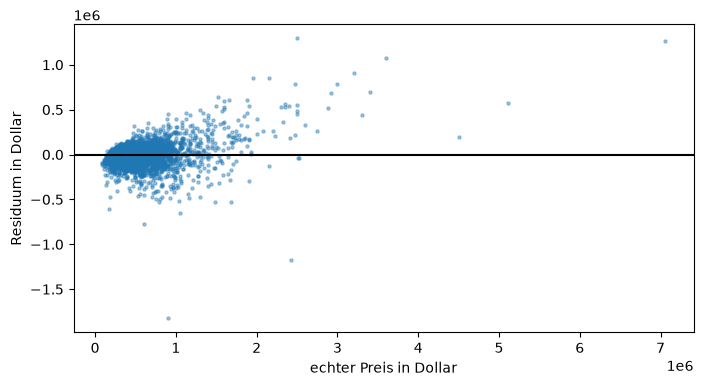

In [20]:
# Residuen gegen den echten Preis: Wo liegt das Modell falsch?
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(y_test, residuals, s=5, alpha=0.4)
ax.axhline(0, color="black")
ax.set_xlabel("echter Preis in Dollar")
ax.set_ylabel("Residuum in Dollar")
plt.show()

👀 Worauf achten:

| Preis-Viertel | Mittleres absolutes Residuum in Dollar |
| :--- | ---: |
| bis 319.800 | 44.972 |
| bis 450.000 | 52.729 |
| bis 637.500 | 68.239 |
| bis 7.060.000 | 137.264 |

- Die Fehler wachsen mit dem Preis, im teuersten Viertel auf etwa das 3-Fache.
- 298 Test-Häuser oder 6,9 % liegen mehr als 200.000 Dollar daneben.
- Der größte Fehler: ein Haus mit 7.120 Quadrat-Fuß, verkauft für 900.000 Dollar, vorhergesagt 2.726.355 Dollar.

## 📌 Merke

1. Prüfe den Schlüssel, bevor du zwei Tabellen verknüpfst.
2. Trenn die Test-Daten zuerst ab und öffne sie erst am Ende.
3. Schreib alle Änderungen von Hand in eine Funktion für beide Teile.
4. Pack jede gelernte Vorbereitung in eine Pipeline.
5. Wähle Modelle mit Kreuz-Validierung und bewerte sie dann gegen beide Basis-Modelle.

---

➡️ Weiter zur [Zusammenfassung](zusammenfassung.ipynb) oder zur [ausführlichen Zusammenfassung](zusammenfassung_lang.ipynb)

📚 Glossar aller Begriffe: [zusammenfassung.ipynb#glossar](zusammenfassung.ipynb#glossar)